# Interactive velocity and force ellipses

**Chapter 5 · L4 slides 30 and 34**

Move the joint-angle sliders of a planar 2R arm and compare its velocity and force capabilities. The task is **tool position $(x,y)$ in fixed world axes**. Both links are 1 m long. Joint angles are displayed in degrees and converted to radians for computation.

Run all cells in JupyterLab or VS Code, using the repository's Python environment. Dependencies are in `requirements.txt`; **Pinocchio is not needed for this analytic 2R example**. GitHub shows the saved example, while live sliders require running the notebook.

The two ideal bounds are $\|\dot q\|_2\le1$ rad/s and $\|\tau\|_2\le1$ N m. They are Euclidean balls, not independent per-joint limits. The force plot shows the static wrench/torque relation only; gravity, dynamics, strength, and contact limitations are not included.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 105, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("NumPy", np.__version__, "| ipywidgets", widgets.__version__)

NumPy 2.3.5 | ipywidgets 8.1.9


## The matrix being visualized

For $c_1=\cos q_1$, $s_1=\sin q_1$, $c_{12}=\cos(q_1+q_2)$ and $s_{12}=\sin(q_1+q_2)$,
$$
p=\begin{bmatrix}c_1+c_{12}\\s_1+s_{12}\end{bmatrix},\qquad
J_p=\begin{bmatrix}-s_1-s_{12}&-s_{12}\\c_1+c_{12}&c_{12}\end{bmatrix},\qquad A=J_pJ_p^T.
$$
If $A=U\operatorname{diag}(\lambda_1,\lambda_2)U^T$, the **velocity semiaxis lengths are $\sqrt{\lambda_i}=\sigma_i$**, along columns of $U$. They are not $\lambda_i$. At full rank, force semiaxis lengths are $1/\sigma_i$ along the same directions.

For slide 30, $u=J_p\dot q$. More generally, if $J$ has full row rank, every solution is $\dot q=J^T(JJ^T)^{-1}u+z$, $z\in\mathcal N(J)$. The two terms are orthogonal, so
$$
\|\dot q\|^2=u^T(JJ^T)^{-1}u+\|z\|^2.
$$
A rate within the unit ball exists exactly when $u^T(JJ^T)^{-1}u\le1$, choosing $z=0$ for the smallest norm.

For slide 34, $\tau=J_p^TF$ gives
$$
\|\tau\|^2=F^TJ_pJ_p^TF=F^TAF\le1.
$$
At a singularity, the velocity set becomes a line segment. The admissible force set becomes a strip, unbounded along $\mathcal N(J_p^T)$. This is a passive reaction direction of the ideal model, not a claim of unlimited actuator strength.

In [2]:
def arm_geometry(q_rad):
    q1, q2 = np.asarray(q_rad, dtype=float)
    elbow = np.array([np.cos(q1), np.sin(q1)])
    tip = elbow + np.array([np.cos(q1 + q2), np.sin(q1 + q2)])
    J = np.array([[-np.sin(q1) - np.sin(q1 + q2), -np.sin(q1 + q2)],
                  [np.cos(q1) + np.cos(q1 + q2),  np.cos(q1 + q2)]])
    return np.vstack((np.zeros(2), elbow, tip)), J


def ellipse_state(q1_deg, q2_deg):
    points, J = arm_geometry(np.deg2rad([q1_deg, q2_deg]))
    A = J @ J.T
    U, sigma, _ = np.linalg.svd(J)
    rank = int(np.count_nonzero(sigma > 1e-10))
    force_lengths = np.full(2, np.inf)
    np.divide(1., sigma, out=force_lengths, where=sigma > 1e-10)
    return dict(points=points, J=J, A=A, U=U, sigma=sigma,
                eigenvalues=sigma**2, rank=rank, force_lengths=force_lengths)

## Check the geometry and limiting cases

Finite differences of forward kinematics independently check the Jacobian. The remaining checks verify the plotted bounds, singular configurations, and invariance of ellipse lengths to a base-angle rotation.

In [3]:
state = ellipse_state(25., 70.)
q = np.deg2rad([25., 70.])
h = 1e-6
J_fd = np.column_stack([
    (arm_geometry(q + h*d)[0][-1] - arm_geometry(q - h*d)[0][-1]) / (2*h)
    for d in np.eye(2)
])
np.testing.assert_allclose(state["J"], J_fd, atol=2e-9)
angles = np.linspace(0., 2*np.pi, 241)
unit_circle = np.vstack((np.cos(angles), np.sin(angles)))
velocities = state["J"] @ unit_circle
velocity_cost = np.sum(velocities * np.linalg.solve(state["A"], velocities), axis=0)
np.testing.assert_allclose(velocity_cost, 1., atol=2e-12)
forces = state["U"] @ (state["force_lengths"][:, None] * unit_circle)
np.testing.assert_allclose(np.linalg.norm(state["J"].T @ forces, axis=0), 1., atol=2e-12)
for q2 in [0., 180., -180.]:
    singular = ellipse_state(35., q2)
    assert singular["rank"] == 1
    np.testing.assert_allclose(singular["J"].T @ (1000*singular["U"][:, 1]),
                               np.zeros(2), atol=1e-10)
np.testing.assert_allclose(state["sigma"], ellipse_state(110., 70.)["sigma"], atol=1e-12)
print("Jacobian finite-difference error:", np.max(np.abs(state["J"]-J_fd)))
print("Velocity boundary, force boundary, and singular cases: all checks passed.")

Jacobian finite-difference error: 9.318856797335684e-11
Velocity boundary, force boundary, and singular cases: all checks passed.


In [4]:
COLORS = {"blue": "#0065BD", "orange": "#D57822", "green": "#17836F"}

def plot_ellipses(q1_deg=25., q2_deg=70.):
    s = ellipse_state(q1_deg, q2_deg)
    J, A, U, sigma = s["J"], s["A"], s["U"], s["sigma"]
    fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.6), layout="constrained")
    ax_robot, ax_velocity, ax_force = axes
    for ax in axes:
        ax.set_aspect("equal")
        ax.axhline(0, color="0.78", linewidth=.7)
        ax.axvline(0, color="0.78", linewidth=.7)
        ax.grid(alpha=.17)
    points = s["points"]
    for i, color in enumerate([COLORS["blue"], COLORS["orange"]]):
        ax_robot.plot(points[i:i+2, 0], points[i:i+2, 1], "o-",
                      color=color, linewidth=4, markersize=6)
    ax_robot.scatter(*points[-1], color=COLORS["green"], s=55, zorder=5)
    ax_robot.annotate("tool", points[-1], xytext=(8, 8), textcoords="offset points")
    ax_robot.set(xlim=(-2.25, 2.25), ylim=(-2.25, 2.25), xlabel="World x (m)",
                 ylabel="World y (m)", title=f"2R arm: q1={q1_deg:.0f}°, q2={q2_deg:.0f}°")
    ax_robot.text(.02, .02, "z out of page; positive angles counterclockwise",
                  transform=ax_robot.transAxes, fontsize=8)

    t = np.linspace(0, 2*np.pi, 721)
    circle = np.vstack((np.cos(t), np.sin(t)))
    velocity_boundary = J @ circle  # Works even when J loses rank; no inverse.
    ax_velocity.fill(*velocity_boundary, color=COLORS["blue"], alpha=.13)
    ax_velocity.plot(*velocity_boundary, color=COLORS["blue"], linewidth=2.2)
    for i, color in enumerate([COLORS["green"], COLORS["orange"]]):
        v_axis = U[:, i] * sigma[i]
        ax_velocity.plot([-v_axis[0], v_axis[0]], [-v_axis[1], v_axis[1]],
                         "--", color=color, linewidth=1.5,
                         label=fr"$\sigma_{i+1}={sigma[i]:.3f}$")
    ax_velocity.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), xlabel="Tool vx (m/s)",
                    ylabel="Tool vy (m/s)", title="Velocity set: ||q̇|| ≤ 1 rad/s")
    ax_velocity.legend(loc="upper right", fontsize=9)
    if s["rank"] < 2:
        ax_velocity.text(.03, .04, "Rank 1: ellipse collapses to a segment",
                         transform=ax_velocity.transAxes, color=COLORS["blue"], fontsize=9)

    # Evaluate F^T A F on a fixed force window. This also draws a correct strip
    # at singularity and avoids replacing a zero singular value by an epsilon.
    extent = 3.2
    grid = np.linspace(-extent, extent, 401)
    fx, fy = np.meshgrid(grid, grid)
    cost = A[0, 0]*fx**2 + 2*A[0, 1]*fx*fy + A[1, 1]*fy**2
    ax_force.contourf(fx, fy, cost, levels=[-1., 1.], colors=[COLORS["orange"]], alpha=.18)
    ax_force.contour(fx, fy, cost, levels=[1.], colors=[COLORS["orange"]], linewidths=2.)
    for i, color in enumerate([COLORS["green"], COLORS["orange"]]):
        length = s["force_lengths"][i]
        direction = U[:, i]
        shown = min(length, 2.85)
        v_axis = direction * shown
        label = (fr"$1/\sigma_{i+1}={length:.3f}$" if np.isfinite(length)
                 else "unbounded reaction direction")
        ax_force.plot([-v_axis[0], v_axis[0]], [-v_axis[1], v_axis[1]],
                      "--", color=color, linewidth=1.4, label=label)
        if not np.isfinite(length):
            ax_force.annotate("", v_axis, xytext=-v_axis,
                              arrowprops=dict(arrowstyle="<->", color=color, lw=1.7))
    ax_force.set(xlim=(-extent, extent), ylim=(-extent, extent), xlabel="Force Fx (N)",
                 ylabel="Force Fy (N)", title="Force set: ||τ|| ≤ 1 N m")
    ax_force.legend(loc="upper right", fontsize=8)
    note = ("Rank 1: strip, unbounded along null(Jᵀ)" if s["rank"] < 2 else
            "Fixed ±3.2 N view; the ellipse may extend outside")
    ax_force.text(.03, .04, note, transform=ax_force.transAxes, fontsize=8)
    return fig, s


def matrix_tex(matrix):
    rows = [" & ".join(f"{x:.3f}" for x in row) for row in matrix]
    return r"\begin{bmatrix}" + r" \\ ".join(rows) + r"\end{bmatrix}"


def state_text(s):
    return (r"$$J_p=" + matrix_tex(s["J"]) + r",\qquad J_pJ_p^T=" + matrix_tex(s["A"]) + "$$\n\n"
            + f"**rank(J_p) = {s['rank']}**. Eigenvalues of J_p J_p^T: "
            + ", ".join(f"{x:.4f}" for x in s["eigenvalues"]) + ". "
            + "Velocity semiaxes are their square roots; force semiaxes are their reciprocals.")

## Saved example

The dashed lines show the shared principal directions. Each panel has its own physical units and fixed axis limits. The force panel is a window into the admissible set; a clipped set has not been artificially capped.

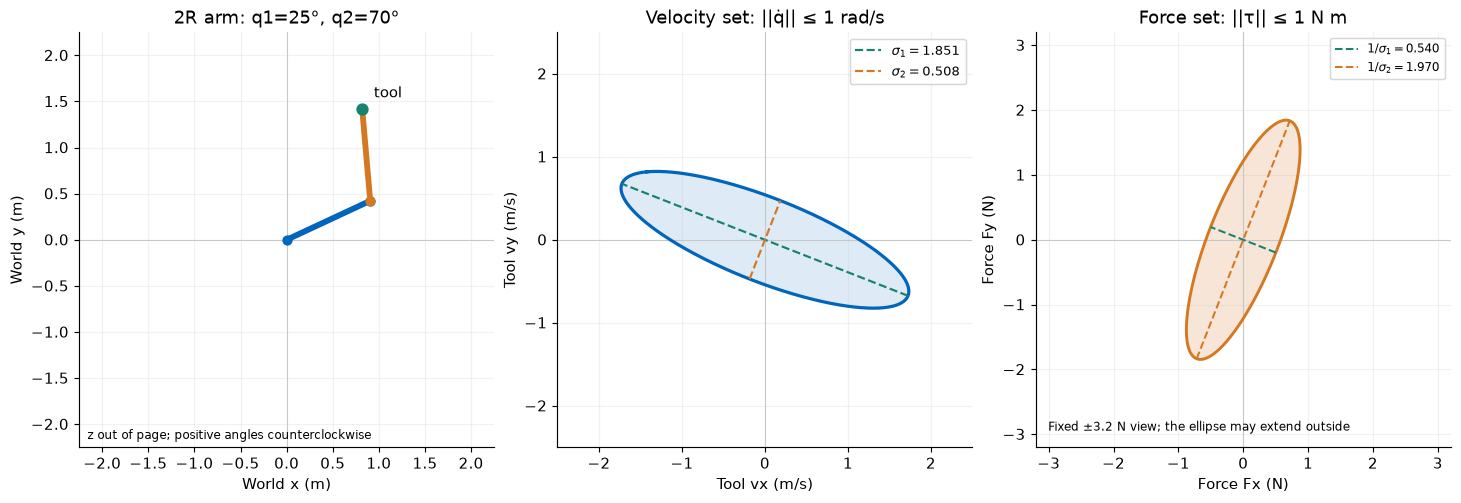

$$J_p=\begin{bmatrix}-1.419 & -0.996 \\ 0.819 & -0.087\end{bmatrix},\qquad J_pJ_p^T=\begin{bmatrix}3.005 & -1.075 \\ -1.075 & 0.679\end{bmatrix}$$

**rank(J_p) = 2**. Eigenvalues of J_p J_p^T: 3.4263, 0.2577. Velocity semiaxes are their square roots; force semiaxes are their reciprocals.

In [5]:
fig, s = plot_ellipses(25., 70.)
display(fig)
plt.close(fig)
display(Markdown(state_text(s)))

## Play with the joint values

Run this cell, then move either slider. Release a slider to update the plots. Presets show a regular posture, straight-arm singularity, and folded-arm singularity.

- Change **q1** while holding q2 fixed: the ellipse rotates, while its semiaxis lengths stay unchanged.
- Move **q2 toward 0° or ±180°**: one velocity semiaxis vanishes and the corresponding force direction becomes unbounded in the ideal model.
- Away from singularity, compare a long velocity semiaxis with its short force counterpart.

In [6]:
q1_slider = widgets.FloatSlider(value=25., min=-180., max=180., step=1.,
    description="q1 (deg)", continuous_update=False, readout_format=".0f",
    layout=widgets.Layout(width="48%"))
q2_slider = widgets.FloatSlider(value=70., min=-180., max=180., step=1.,
    description="q2 (deg)", continuous_update=False, readout_format=".0f",
    layout=widgets.Layout(width="48%"))
out = widgets.Output()
latest_gui_state = {}

def redraw(change=None):
    fig, s = plot_ellipses(q1_slider.value, q2_slider.value)
    latest_gui_state.update(q1=q1_slider.value, q2=q2_slider.value, rank=s["rank"], A=s["A"])
    with out:
        clear_output(wait=True)
        display(fig)
        display(Markdown(state_text(s)))
    plt.close(fig)

q1_slider.observe(redraw, names="value")
q2_slider.observe(redraw, names="value")
buttons = []
for label, q1_value, q2_value in [("Regular", 25., 70.), ("Straight", 0., 0.), ("Folded", 0., 180.)]:
    button = widgets.Button(description=label)
    def choose_preset(_button, a=q1_value, b=q2_value):
        q1_slider.value = a
        q2_slider.value = b
        redraw()
    button.on_click(choose_preset)
    buttons.append(button)
display(widgets.VBox([widgets.HBox([q1_slider, q2_slider]), widgets.HBox(buttons), out]))
redraw()

Run this cell in JupyterLab or VS Code to display the interactive sliders.

The plotting code uses the forward map `J @ unit_circle` for the velocity set and the inequality `F.T @ (J @ J.T) @ F <= 1` for the force set. Both remain meaningful at rank loss. No matrix inverse or artificial damping is used to hide the singularity.

For slider API details, see the [official ipywidgets examples](https://ipywidgets.readthedocs.io/en/stable/examples/Widget%20List.html). To retrieve geometric Jacobians and accelerations from a robot library, use the [Pinocchio notebook](02_pinocchio_analytic_jacobians_and_accelerations.ipynb).